# Model evaluation

Blend of a date-weighted ridge regression and a smoothed direct maximisation of the cosine metric.
See `README.md` at the repository root for the mathematical description.

In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qrt_model import (load_data, score, check_stiefel, fit, fit_ridge, ridge_w, cos_w, blend_w,
                       cv_repeated, summary, read_submission)

X, y, stock_id, date = load_data("../data")
assert X.shape == (25200, 250) and y.shape == (25200,)
print(X.shape, y.shape)

(25200, 250) (25200,)


In [2]:
# normalised components of the blend and final weights
w_ridge = ridge_w(X, y)
w_ridge /= np.linalg.norm(w_ridge)
w_cos = cos_w(X, y, w0=w_ridge)
w = blend_w(X, y)
assert np.allclose(w, w_ridge + w_cos)
print("cosine between the two components:", round(w_ridge @ w_cos, 3))

cosine between the two components: 0.939


In [3]:
# in-sample score (50 training stocks)
A, beta = fit(X, y)
assert check_stiefel(A)
assert np.allclose(A @ beta, w)
in_sample = {"weighted ridge": score(y, X @ w_ridge), "smoothed cosine": score(y, X @ w_cos), "blend": score(y, X @ w)}
pd.Series(in_sample).round(4)

weighted ridge     0.1407
smoothed cosine    0.1478
blend              0.1462
dtype: float64

In [4]:
# cross-validation across stocks: 5 splits x 5 folds, paired gains against the weighted ridge
s_ridge = cv_repeated(fit_ridge, X, y, stock_id)
s_model = cv_repeated(fit, X, y, stock_id)
res = pd.DataFrame({"weighted ridge": summary(s_ridge), "blend": summary(s_model, s_ridge)}).T
assert res.loc["blend", "gain"] > 2 * res.loc["blend", "se_gain"]
res.round(4)

,cv,se,gain,se_gain
weighted ridge,0.0521,0.0052,NaN,NaN
blend,0.0557,0.0058,0.0037,0.0013


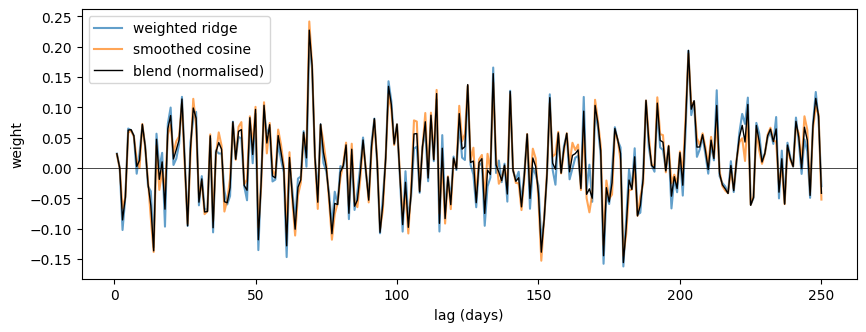

In [5]:
# weights by lag
plt.figure(figsize=(10, 3.5))
lags = np.arange(1, 251)
plt.plot(lags, w_ridge, alpha=0.7, label="weighted ridge")
plt.plot(lags, w_cos, alpha=0.7, label="smoothed cosine")
plt.plot(lags, w / np.linalg.norm(w), color="k", lw=1, label="blend (normalised)")
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("lag (days)")
plt.ylabel("weight")
plt.legend()
plt.show()

In [6]:
# the submitted file matches the model
A_sub, beta_sub = read_submission("../submissions/final_submission.csv")
assert check_stiefel(A_sub)
assert np.allclose(A_sub, A) and np.allclose(beta_sub, beta)
print("submission matches, in-sample score:", round(score(y, X @ A_sub @ beta_sub), 4))

submission matches, in-sample score: 0.1462
